In [3]:
!pip install -q tensorflow tensorflow-datasets matplotlib

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

print(tf.__version__)

2.21.0


In [5]:
dataset, info = tfds.load('oxford_iiit_pet', with_info=True)
print(info.splits)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

W0000 00:00:1785190458.049254    4680 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1785190458.305206    4142 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentione

Shuffling /home/saidislom_01/tensorflow_datasets/oxford_iiit_pet/incomplete.N3TMJS_4.0.0/oxford_iiit_pet-train…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /home/saidislom_01/tensorflow_datasets/oxford_iiit_pet/incomplete.N3TMJS_4.0.0/oxford_iiit_pet-test.…

Dataset oxford_iiit_pet downloaded and prepared to /home/saidislom_01/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
{'train': <SplitInfo num_examples=3680, num_shards=4>, 'test': <SplitInfo num_examples=3669, num_shards=4>}


In [8]:
IMG_SIZE = 128

def load_image(datapoint, augment=False):
    input_image = tf.image.resize(datapoint['image'], (IMG_SIZE, IMG_SIZE))
    input_mask = tf.image.resize(
        datapoint['segmentation_mask'], (IMG_SIZE, IMG_SIZE),
        method='nearest'  # nearest keeps mask values as integers
    )

    if augment and tf.random.uniform(()) > 0.5:
        input_image = tf.image.flip_left_right(input_image)
        input_mask = tf.image.flip_left_right(input_mask)

    input_image = tf.cast(input_image, tf.float32) / 255.0
    input_mask -= 1  # {1,2,3} -> {0,1,2}
    return input_image, input_mask

In [9]:
BATCH_SIZE = 32
BUFFER_SIZE = 1000

train_images = dataset['train'].map(lambda x: load_image(x, augment=True),
                                     num_parallel_calls=tf.data.AUTOTUNE)
test_images = dataset['test'].map(lambda x: load_image(x, augment=False),
                                   num_parallel_calls=tf.data.AUTOTUNE)

train_batches = (train_images
                  .cache()
                  .shuffle(BUFFER_SIZE)
                  .batch(BATCH_SIZE)
                  .prefetch(tf.data.AUTOTUNE))
test_batches = test_images.batch(BATCH_SIZE)

# sanity check
for img, mask in train_batches.take(1):
    print(img.shape, mask.shape)  # (32,128,128,3) (32,128,128,1)

I0000 00:00:1785192895.874921    4889 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


(32, 128, 128, 3) (32, 128, 128, 1)


W0000 00:00:1785192896.348366    4894 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


W0000 00:00:1785192930.084074    5005 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


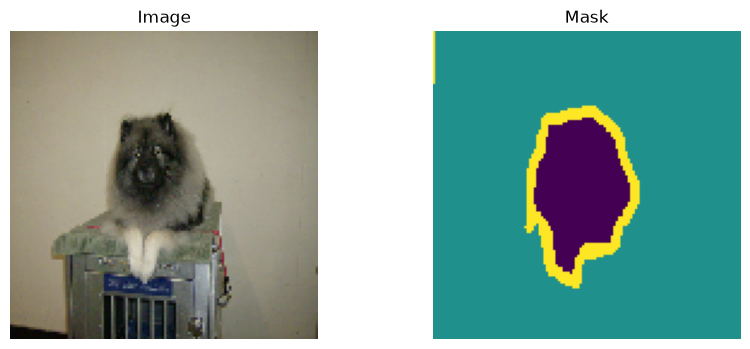

In [10]:
def display(display_list, titles):
    plt.figure(figsize=(10, 4))
    for i, item in enumerate(display_list):
        plt.subplot(1, len(display_list), i+1)
        plt.title(titles[i])
        plt.imshow(item)
        plt.axis('off')
    plt.show()

for img, mask in train_batches.take(1):
    display([img[0], mask[0]], ['Image', 'Mask'])

In [11]:
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    return x

def build_unet(input_shape=(128, 128, 3), num_classes=3):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 64);   p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 128);      p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 256);      p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 512);      p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    bn = conv_block(p4, 1024)

    # Decoder (upsample + concat skip connection + conv_block)
    u6 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(bn)
    u6 = layers.Concatenate()([u6, c4]); c6 = conv_block(u6, 512)

    u7 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = layers.Concatenate()([u7, c3]); c7 = conv_block(u7, 256)

    u8 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = layers.Concatenate()([u8, c2]); c8 = conv_block(u8, 128)

    u9 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    u9 = layers.Concatenate()([u9, c1]); c9 = conv_block(u9, 64)

    outputs = layers.Conv2D(num_classes, 1, activation='softmax')(c9)

    return Model(inputs, outputs, name='unet')

model = build_unet()
model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,875 (118.38 MB)

 Trainable params: 31,031,875 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [13]:
EPOCHS = 20
TRAIN_LENGTH = info.splits['train'].num_examples
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE

history = model.fit(
    train_batches,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=test_batches
)

Epoch 1/20


/mnt/c/Users/user/Desktop/projects/Deep Learning/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


115/115 ━━━━━━━━━━━━━━━━━━━━ 514s 4s/step - accuracy: 0.5793 - loss: 0.8984 - val_accuracy: 0.6078 - val_loss: 0.7915
Epoch 2/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 509s 4s/step - accuracy: 0.7176 - loss: 0.6859 - val_accuracy: 0.7414 - val_loss: 0.6331
Epoch 3/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 506s 4s/step - accuracy: 0.7571 - loss: 0.6041 - val_accuracy: 0.7726 - val_loss: 0.5799
Epoch 4/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 504s 4s/step - accuracy: 0.7939 - loss: 0.5246 - val_accuracy: 0.8115 - val_loss: 0.4845
Epoch 5/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 505s 4s/step - accuracy: 0.8197 - loss: 0.4645 - val_accuracy: 0.8338 - val_loss: 0.4287
Epoch 6/20
115/115 ━━━━━━━━━━━━━━━━━━━━ 504s 4s/step - accuracy: 0.8334 - loss: 0.4326 - val_accuracy: 0.8460 - val_loss: 0.4005
Epoch 7/20
 21/115 ━━━━━━━━━━━━━━━━━━━━ 5:07 3s/step - accuracy: 0.8516 - loss: 0.3840

KeyboardInterrupt: 